# **IMPORTING THE DEPENDENCIES**

In [50]:
import numpy as np , pandas as pd , seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split ,KFold, cross_validate , GridSearchCV
from sklearn.preprocessing import OneHotEncoder , StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge , Lasso , LinearRegression
from sklearn.metrics import (
                mean_squared_error ,
                root_mean_squared_error,
                mean_absolute_error,
                r2_score
)
from sklearn.ensemble import RandomForestRegressor , HistGradientBoostingRegressor
import warnings 
warnings.filterwarnings('ignore')


# **LOADING THE DATASET**

In [51]:
# Dataset URL
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Load dataset
housing_data = pd.read_csv(url)

# Display first 5 rows
housing_data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [52]:
housing_data.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


# **Exploratory Data Analysis (EDA)**

In [53]:
housing_data.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [54]:
#Inspect the dataset

print("Dataset Shape:", housing_data.shape)

print("\nDataset Information:")
housing_data.info()

print("\nStatistical Summary:")
housing_data.describe()

Dataset Shape: (20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


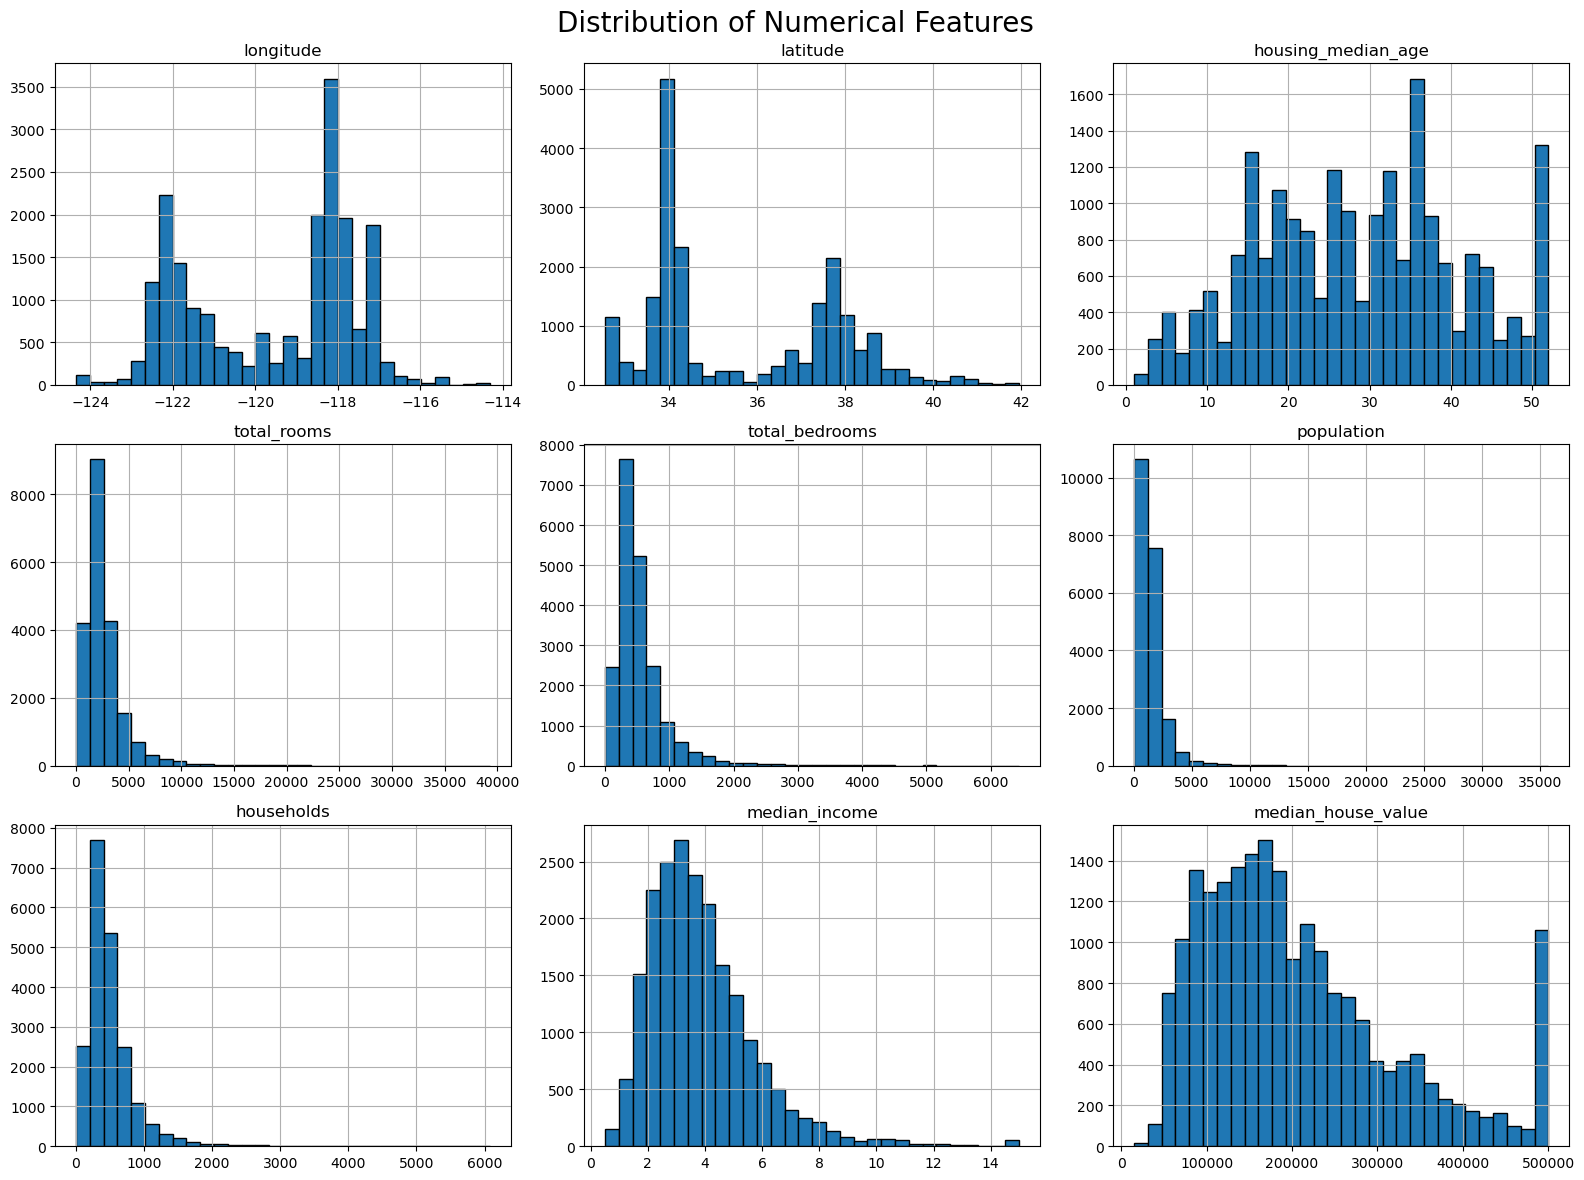

In [55]:
num_cols = housing_data.select_dtypes(include = np.number).columns.tolist()
cat_cols = housing_data.select_dtypes(include = 'object').columns.tolist()
housing_data[num_cols].hist(
    figsize = (16,12),
    bins = 30 ,
    edgecolor = 'black'
)
plt.suptitle('Distribution of Numerical Features',fontsize = 20)
plt.tight_layout()
plt.show()

In [56]:
# Check missing values
print("Missing Values:")
print(housing_data.isnull().sum())

# Check percentage of missing values
print("\nMissing Values Percentage:")
print((housing_data.isnull().sum() / len(housing_data)) * 100)

# Check categorical values
print("\nOcean Proximity Categories:")
print(housing_data["ocean_proximity"].value_counts())

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing Values Percentage:
longitude             0.000000
latitude              0.000000
housing_median_age    0.000000
total_rooms           0.000000
total_bedrooms        1.002907
population            0.000000
households            0.000000
median_income         0.000000
median_house_value    0.000000
ocean_proximity       0.000000
dtype: float64

Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [57]:
housing_data.duplicated().sum()

np.int64(0)

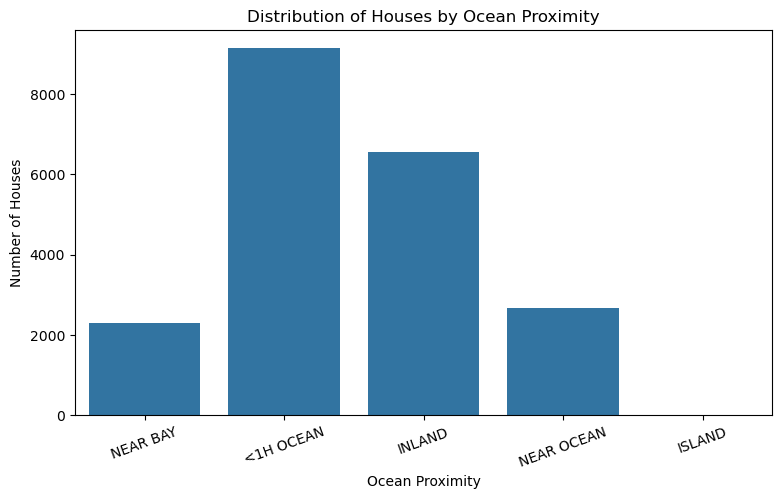

In [58]:
# Visualize ocean proximity
plt.figure(figsize = (9 , 5))
sns.countplot(
    data = housing_data,
    x = 'ocean_proximity'
)
plt.title('Distribution of Houses by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Number of Houses')
plt.xticks(rotation = 20)
plt.show()

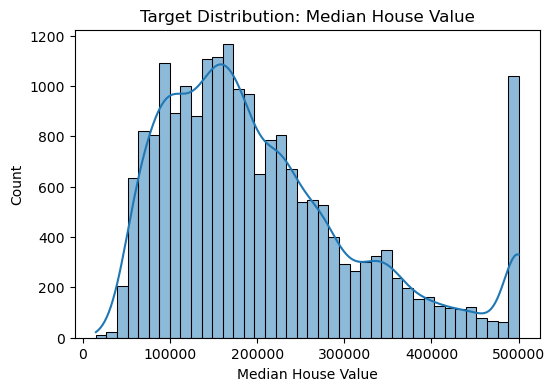

In [59]:
# target column distribution
plt.figure(figsize=(6,4))
sns.histplot(housing_data['median_house_value'], bins=40, kde=True)
plt.title("Target Distribution: Median House Value")
plt.xlabel("Median House Value")
plt.show()

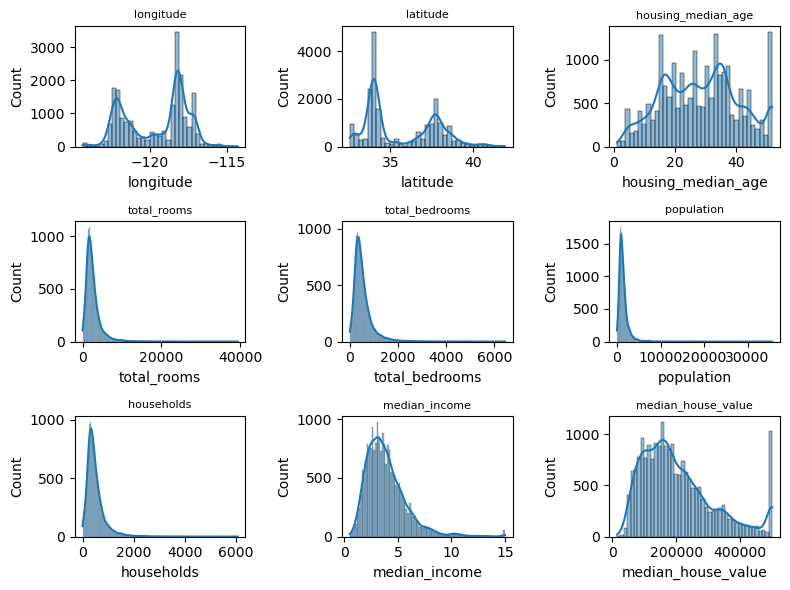

In [60]:
# Histogram plot distribution 

fig , axes = plt.subplots(3,3, figsize = (8,6))
axes  = axes.flatten()

for i , cols in enumerate(num_cols):
    sns.histplot(housing_data[cols] , kde = True , ax = axes[i])
    axes[i].set_title(cols , fontsize = (8))

plt.tight_layout()
plt.show()

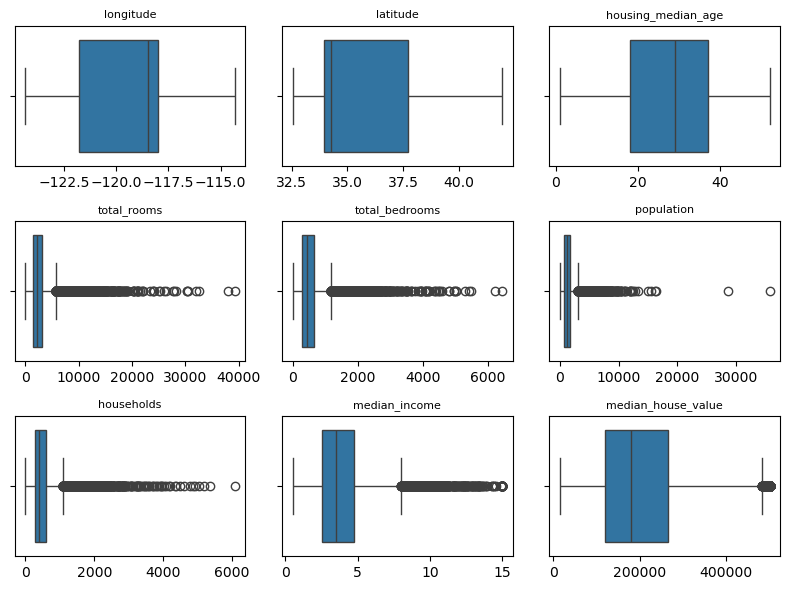

In [61]:
# OUTLIER ANALYSIS

fig , axes = plt.subplots( 3, 3 , figsize = (8,6))
axes = axes.flatten()
for i , cols in enumerate(num_cols):
    sns.boxplot(x = housing_data[cols] , ax = axes[i])
    axes[i].set_title(cols, fontsize = (8))
    axes[i].set_xlabel("")


plt.tight_layout()
plt.show()

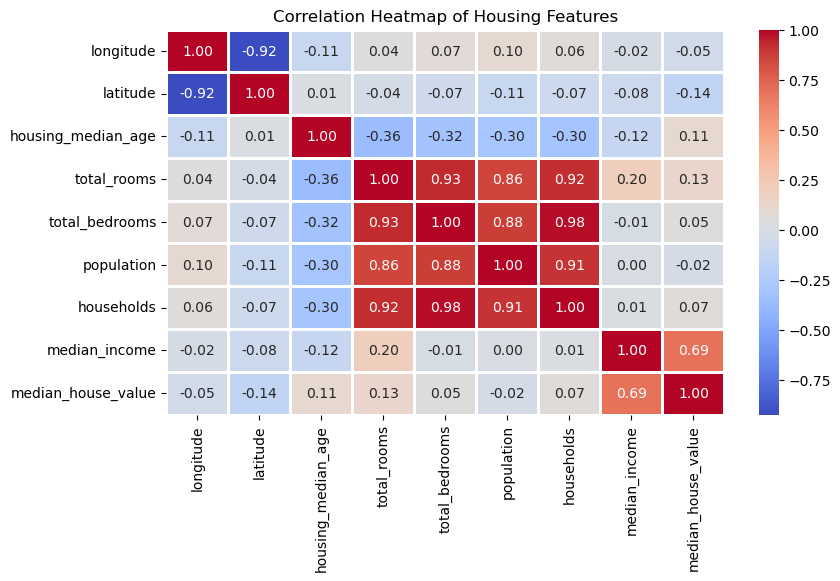

In [62]:
# Calculate correlation between numerical columns
correlation_metrics = housing_data.select_dtypes(include = np.number).corr()

plt.figure(figsize = (9 , 5))
sns.heatmap(
    correlation_metrics , 
    annot = True , 
    cmap = 'coolwarm',
    fmt = '.2f',
    linewidth = 1
)
plt.title("Correlation Heatmap of Housing Features")
plt.show()

In [63]:
# Saperate input featues and target variable
X = housing_data.drop(columns = ['median_house_value'],axis =1 )
Y = housing_data['median_house_value']



# Display their shapes
print("Features shape:", X.shape)
print("Target shape:", Y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


#**SPLITING  THE DATASET INTO TRAINING AND TESTING**

In [64]:
X_train , X_test , Y_train , Y_test  = train_test_split( X , Y , test_size = 0.2 , random_state = 42)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", Y_train.shape)
print("Testing target:", Y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


# **BUILDING PREPROCESSING PIPELINE**

In [65]:
numerical_features = X_train.select_dtypes(include = np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include = 'object').columns.tolist()

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical Features:
['ocean_proximity']


#**Creating numerical and categorical pipelines**

In [66]:
# Numerical preprocessing pipeline

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy = 'median')),
    ('scaler' , StandardScaler())
])

# Categprical preprocessing pipeline
categorical_pipeline = Pipeline([
    ('imputer' , SimpleImputer(strategy = 'most_frequent')),
    ('encoder' , OneHotEncoder(handle_unknown ='ignore'))
])

In [67]:
preprocessor = ColumnTransformer([
    ('num' , numerical_pipeline , numerical_features),
    ('cat' , categorical_pipeline , categorical_features)
])

In [68]:
# CREATING A BASELINE MODEL
baseline_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LinearRegression())
    ])

In [69]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nColumns expected by your preprocessor:")
print(numerical_features)
print(categorical_features)

X_train columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']

Columns expected by your preprocessor:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
['ocean_proximity']


In [70]:
# Preprocess the data and train the baseline model
baseline_pipe.fit(X_train , Y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# **EVALUATION OF BASELINE MODEL**

In [71]:
train_baseline_pred = baseline_pipe.predict(X_train)
test_baseline_pred = baseline_pipe.predict(X_test)

In [72]:
# TRAINING EVALUATION 
train_baseline_mae = mean_absolute_error(Y_train , train_baseline_pred)

train_baseline_rmse = np.sqrt(mean_squared_error(Y_train , train_baseline_pred))

train_baseline_r2_Squared = r2_score(Y_train , train_baseline_pred)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE:", train_baseline_mae)
print("RMSE:", train_baseline_rmse)
print("R2 Score:",train_baseline_r2_Squared)

Linear Regression Performance
-----------------------------
MAE: 49594.84209472437
RMSE: 68433.93736666226
R2 Score: 0.6496648627123224


In [73]:
# TESTING EVALUATION
test_baseline_mae = mean_absolute_error(Y_test , test_baseline_pred)

test_baseline_rmse = np.sqrt(mean_squared_error(Y_test , test_baseline_pred))

test_baseline_r2_Squared = r2_score(Y_test, test_baseline_pred)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE:", test_baseline_mae)
print("RMSE:", test_baseline_rmse)
print("R2 Score:",test_baseline_r2_Squared)

Linear Regression Performance
-----------------------------
MAE: 50670.489235653615
RMSE: 70059.19333925014
R2 Score: 0.6254382675296266


In [74]:
# MODEL SELECTION & OPTIMIZATION 

models = {
    'LinearRegression' : LinearRegression(),
    'Ridge' : Ridge(random_state = 42),
    'Lasso': Lasso(max_iter = 10000, random_state = 42),
    'RandomForest' : RandomForestRegressor(),
    'HistGB' : HistGradientBoostingRegressor()
}

In [75]:
k = 5
cv = KFold(n_splits = k , shuffle = True , random_state = 42)


In [76]:
scoring = {
    'rmse' : 'neg_root_mean_squared_error',
    'mae' : 'neg_mean_absolute_error',
    'r2' : 'r2'
    
}

In [79]:
rows = []
for name , model in models.items():
    pipe = Pipeline([
        ('preprocess' , preprocessor),
        ('model' , model)
    ])
    scores = cross_validate(pipe, X_train , Y_train ,cv = cv , scoring = scoring ,  n_jobs = 1 )

    rows.append({
        'model' : model ,
        'cv_rmse' : -scores['test_rmse'].mean(),
        'cv_mae' : -scores['test_mae'].mean(),
        'cv_r2' : scores['test_r2'].mean()
    })

cv_results = pd.DataFrame(rows).sort_values('cv_rmse')

print("=== CV Model Comparison ===")
print(cv_results)
    

=== CV Model Comparison ===
                                    model       cv_rmse        cv_mae  \
4         HistGradientBoostingRegressor()  48223.722611  32336.415058   
3                 RandomForestRegressor()  49525.658469  32342.345598   
1                  Ridge(random_state=42)  68595.617399  49664.330927   
2  Lasso(max_iter=10000, random_state=42)  68603.233277  49667.262611   
0                      LinearRegression()  68604.162955  49667.159067   

      cv_r2  
4  0.825998  
3  0.816482  
1  0.647760  
2  0.647685  
0  0.647676  


In [80]:
best_row = cv_results.sort_values('cv_rmse').iloc[0]
best_model = best_row['model']
best_rmse = best_row['cv_rmse']

print(best_model)
print(best_rmse)

HistGradientBoostingRegressor()
48223.72261075934


# **BEST MODEL : HistGradientBoostingRegressor**

# **HYPERPERAMETER TUNING**

In [81]:
hgb_pipe = Pipeline([
    ('preprocess' , preprocessor),
    ('model', HistGradientBoostingRegressor(random_state = 42))
])


In [82]:
# hyperparameters combination
param_grid = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [None, 3, 6],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0]
}

In [83]:
grid = GridSearchCV(
    estimator = hgb_pipe,
    param_grid = param_grid , 
    cv = cv , 
    scoring = 'neg_root_mean_squared_error',
    n_jobs = -1 , 
    verbose = 1 ,
)

In [84]:
grid.fit(X_train , Y_train)

Fitting 5 folds for each of 243 candidates, totalling 1215 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__l2_regularization': [0.0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [None, 3, ...], 'model__max_leaf_nodes': [15, 31, ...], ...}"
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,KFold(n_split... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [85]:
print("\n=== TUNED HistGB (CV) ===")
print('Best CV RMSE' , -grid.best_score_)
print('Best param' , grid.best_params_)


=== TUNED HistGB (CV) ===
Best CV RMSE 47408.35933729127
Best param {'model__l2_regularization': 0.1, 'model__learning_rate': 0.1, 'model__max_depth': None, 'model__max_leaf_nodes': 63, 'model__min_samples_leaf': 20}


# **Retraining with best params**

In [86]:
hgb_best = Pipeline([
    ('preprocess' , preprocessor),
    ('model' , HistGradientBoostingRegressor(
        l2_regularization = 0.1 , 
        learning_rate = 0.1 , 
        max_depth = None , 
        max_leaf_nodes = 63 , 
        min_samples_leaf = 20 , 
    ))
]
                   )


In [87]:
hgb_best.fit(X_train , Y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


# **FINAL EVALUATION**

In [88]:
train_final_pred = hgb_best.predict(X_train)
final_train_rmse = root_mean_squared_error(Y_train , train_final_pred)
final_train_mae = mean_absolute_error(Y_train , train_final_pred)
final_train_r2 = r2_score(Y_train , train_final_pred)


print("\n=== FINAL MODEL (Tuned HGB) Train Performance ===")
print(f"RMSE: {final_train_rmse:.3f}")
print(f"MAE : {final_train_mae:.3f}")
print(f"R2  : {final_train_r2:.3f}")


=== FINAL MODEL (Tuned HGB) Train Performance ===
RMSE: 35965.726
MAE : 24568.789
R2  : 0.903


In [89]:
test_final_pred = hgb_best.predict(X_test)
final_test_rmse = root_mean_squared_error(Y_test , test_final_pred)
final_test_mae = mean_absolute_error(Y_test , test_final_pred)
final_test_r2 = r2_score(Y_test , test_final_pred)


print("\n=== FINAL MODEL (Tuned HGB) Train Performance ===")
print(f"RMSE: {final_test_rmse:.3f}")
print(f"MAE : {final_test_mae:.3f}")
print(f"R2  : {final_test_r2:.3f}")


=== FINAL MODEL (Tuned HGB) Train Performance ===
RMSE: 46654.298
MAE : 30780.948
R2  : 0.834


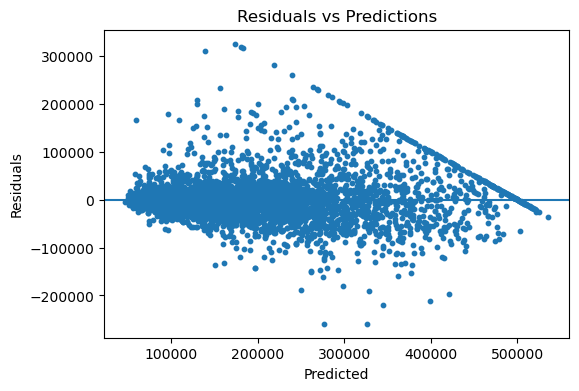

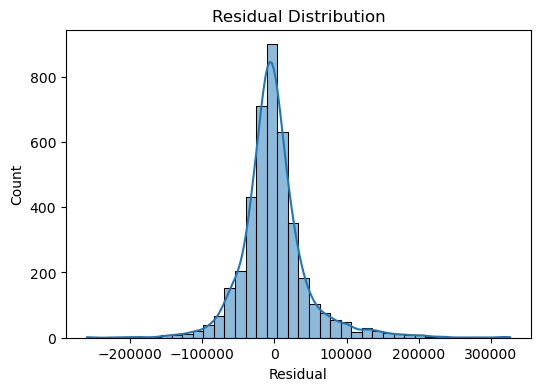

In [90]:
# residual plot
residuals = Y_test - test_final_pred

plt.figure(figsize=(6, 4))
plt.scatter(test_final_pred, residuals, s=10)
plt.axhline(0)
plt.title("Residuals vs Predictions")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(residuals, bins=40, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.show()

# **Building a predictive system**

In [91]:
def predict_house_price(
    model,
    longitude: float,
    latitude: float,
    housing_median_age: float,
    total_rooms: float,
    total_bedrooms: float,
    population: float,
    households: float,
    median_income: float,
    ocean_proximity: str
) -> float:
    """
    Predict median_house_value for one new house.
    total_bedrooms can be np.nan (pipeline will impute).
    """
    new_row = pd.DataFrame([{
        "longitude": longitude,
        "latitude": latitude,
        "housing_median_age": housing_median_age,
        "total_rooms": total_rooms,
        "total_bedrooms": total_bedrooms,
        "population": population,
        "households": households,
        "median_income": median_income,
        "ocean_proximity": ocean_proximity
    }])

    return float(model.predict(new_row)[0])

In [92]:
# Example inference
example_pred = predict_house_price(
    model=hgb_best,
    longitude=-122.22,
    latitude=37.86,
    housing_median_age=21.0,
    total_rooms=7099.0,
    total_bedrooms=1106.0,
    population=2401.0,
    households=1138.0,
    median_income=8.3014,
    ocean_proximity="NEAR BAY"
 )

print("\nExample prediction:", round(example_pred, 2))


Example prediction: 413992.49


In [93]:
housing_data.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [96]:
import joblib

joblib.dump({
    "model": hgb_best,
    "metrics": {
        "RMSE": final_test_rmse,
        "MAE": final_test_mae,
        "R²": final_test_r2,
    },
}, "housing_model_pred.joblib")

['housing_model_pred.joblib']